In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import torch

import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

from src.models.shapformer import SHAPformer

TRAINING = False  # True: train the model from scratch and save it to MODEL_PATH; False: load the trained model from MODEL_PATH
MODEL_PATH = "model.ckpt"

In [2]:
file = "./data/transnet/transnet_bw_hourly.csv"
df = pd.read_csv(file, parse_dates=[0], index_col=0)
df = df.drop(columns="irradiance")
df["month"] -= 1  # categorical features must start at 0
print(df)

                                load  hour_of_day  day_of_week  month  \
cet_cest_timestamp                                                      
2015-01-01 01:00:00+01:00  5279.7900            1            3      0   
2015-01-01 02:00:00+01:00  5024.5425            2            3      0   
2015-01-01 03:00:00+01:00  4879.9750            3            3      0   
2015-01-01 04:00:00+01:00  4858.5250            4            3      0   
2015-01-01 05:00:00+01:00  4600.1400            5            3      0   
...                              ...          ...          ...    ...   
2019-12-31 19:00:00+01:00  5914.4275           19            1     11   
2019-12-31 20:00:00+01:00  5620.2250           20            1     11   
2019-12-31 21:00:00+01:00  5517.5050           21            1     11   
2019-12-31 22:00:00+01:00  5487.2600           22            1     11   
2019-12-31 23:00:00+01:00  5293.9675           23            1     11   

                           holiday  temperature  p

In [3]:
model = SHAPformer(
    target="load",
    feature_categories={
        "hour_of_day": 24,
        "day_of_week": 7,
        "month": 12,
        "holiday": 2,
        "temperature": None,
        "precipitation": None
    },
    d_model=128,
    n_layers=1,
    n_heads=4
)
print(model)

SHAPformer(
  (encoder_embedding): FeatureEmbedding(
    (embeddings): ParameterDict(
        (load): Object of type: LinearEmbedding
        (hour_of_day): Object of type: CategoricalEmbedding
        (day_of_week): Object of type: CategoricalEmbedding
        (month): Object of type: CategoricalEmbedding
        (holiday): Object of type: CategoricalEmbedding
        (temperature): Object of type: LinearEmbedding
        (precipitation): Object of type: LinearEmbedding
      (load): LinearEmbedding(
        (embedding): Linear(in_features=1, out_features=128, bias=True)
      )
      (hour_of_day): CategoricalEmbedding(
        (embedding): Embedding(24, 128)
      )
      (day_of_week): CategoricalEmbedding(
        (embedding): Embedding(7, 128)
      )
      (month): CategoricalEmbedding(
        (embedding): Embedding(12, 128)
      )
      (holiday): CategoricalEmbedding(
        (embedding): Embedding(2, 128)
      )
      (temperature): LinearEmbedding(
        (embedding): Li

In [4]:
DEVICE = "cuda"
VALIDATION_START = "2019-01-01"

if TRAINING:
    model.to(DEVICE)
    model = model.fit(df, VALIDATION_START, batch_size=128, patience=10)
    torch.save(model, MODEL_PATH)
else:
    model = torch.load(MODEL_PATH, map_location=DEVICE, weights_only=False)
    model.eval()

<Axes: xlabel='cet_cest_timestamp'>

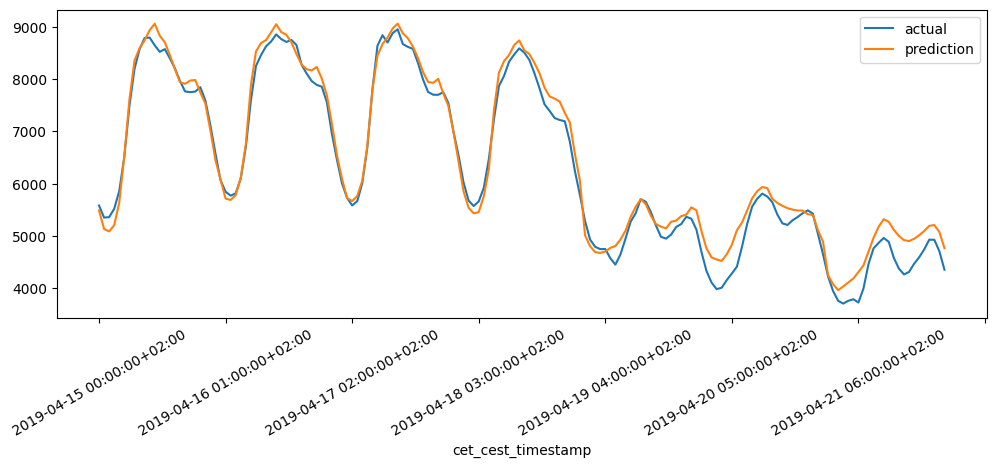

In [5]:
FORECAST_START = "2019-04-15 00:00:00+02:00"
INPUT_LENGTH = HORIZON = 168

start = df.index.get_loc(FORECAST_START)
past = df.iloc[start - INPUT_LENGTH:start]
future = df.iloc[start:start + HORIZON].drop(columns="load")

prediction = model.predict(past, future)

comparison = pd.DataFrame({"actual": df["load"].iloc[start:start + HORIZON], "prediction": prediction})
comparison.plot(figsize=(12, 4), rot=30)

In [6]:
import matplotlib.pyplot as plt

explanation = model.explain(past, future)

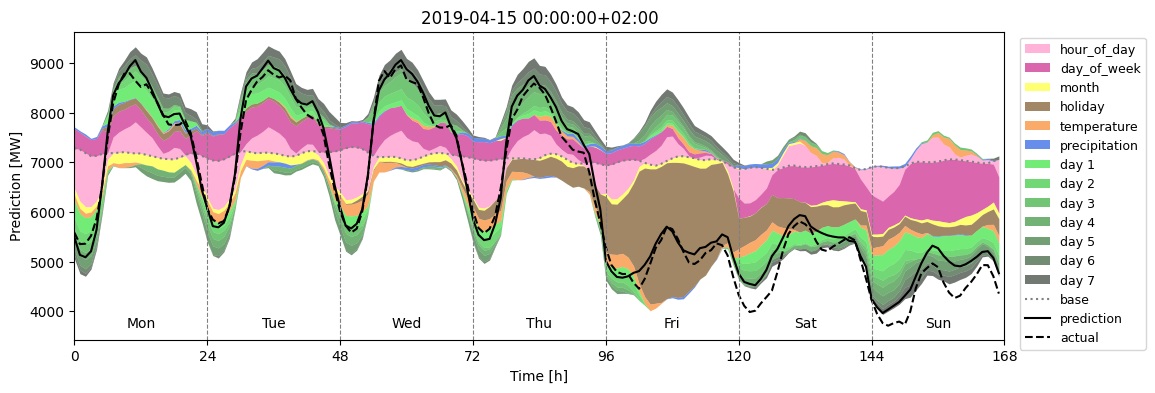

In [7]:
from src.plot import plot_explanation

actual = df["load"].iloc[start:start + HORIZON]
plot_explanation(explanation, actual=actual, title=f"{FORECAST_START}")
plt.show()

In [ ]:
import random

N_EXPLANATIONS = 100
SEED = 42

# forecast starts in the validation period (same split as in fit), at any hour
timestamps = pd.to_datetime(df.index, utc=True)
first_validation_start = int((timestamps < pd.Timestamp(VALIDATION_START, tz="UTC")).sum())
random.seed(SEED)
starts = sorted(random.sample(range(first_validation_start, len(df) - HORIZON + 1), N_EXPLANATIONS))

explanations = [
    model.explain(df.iloc[s - INPUT_LENGTH:s], df.iloc[s:s + HORIZON].drop(columns="load"))
    for s in starts
]

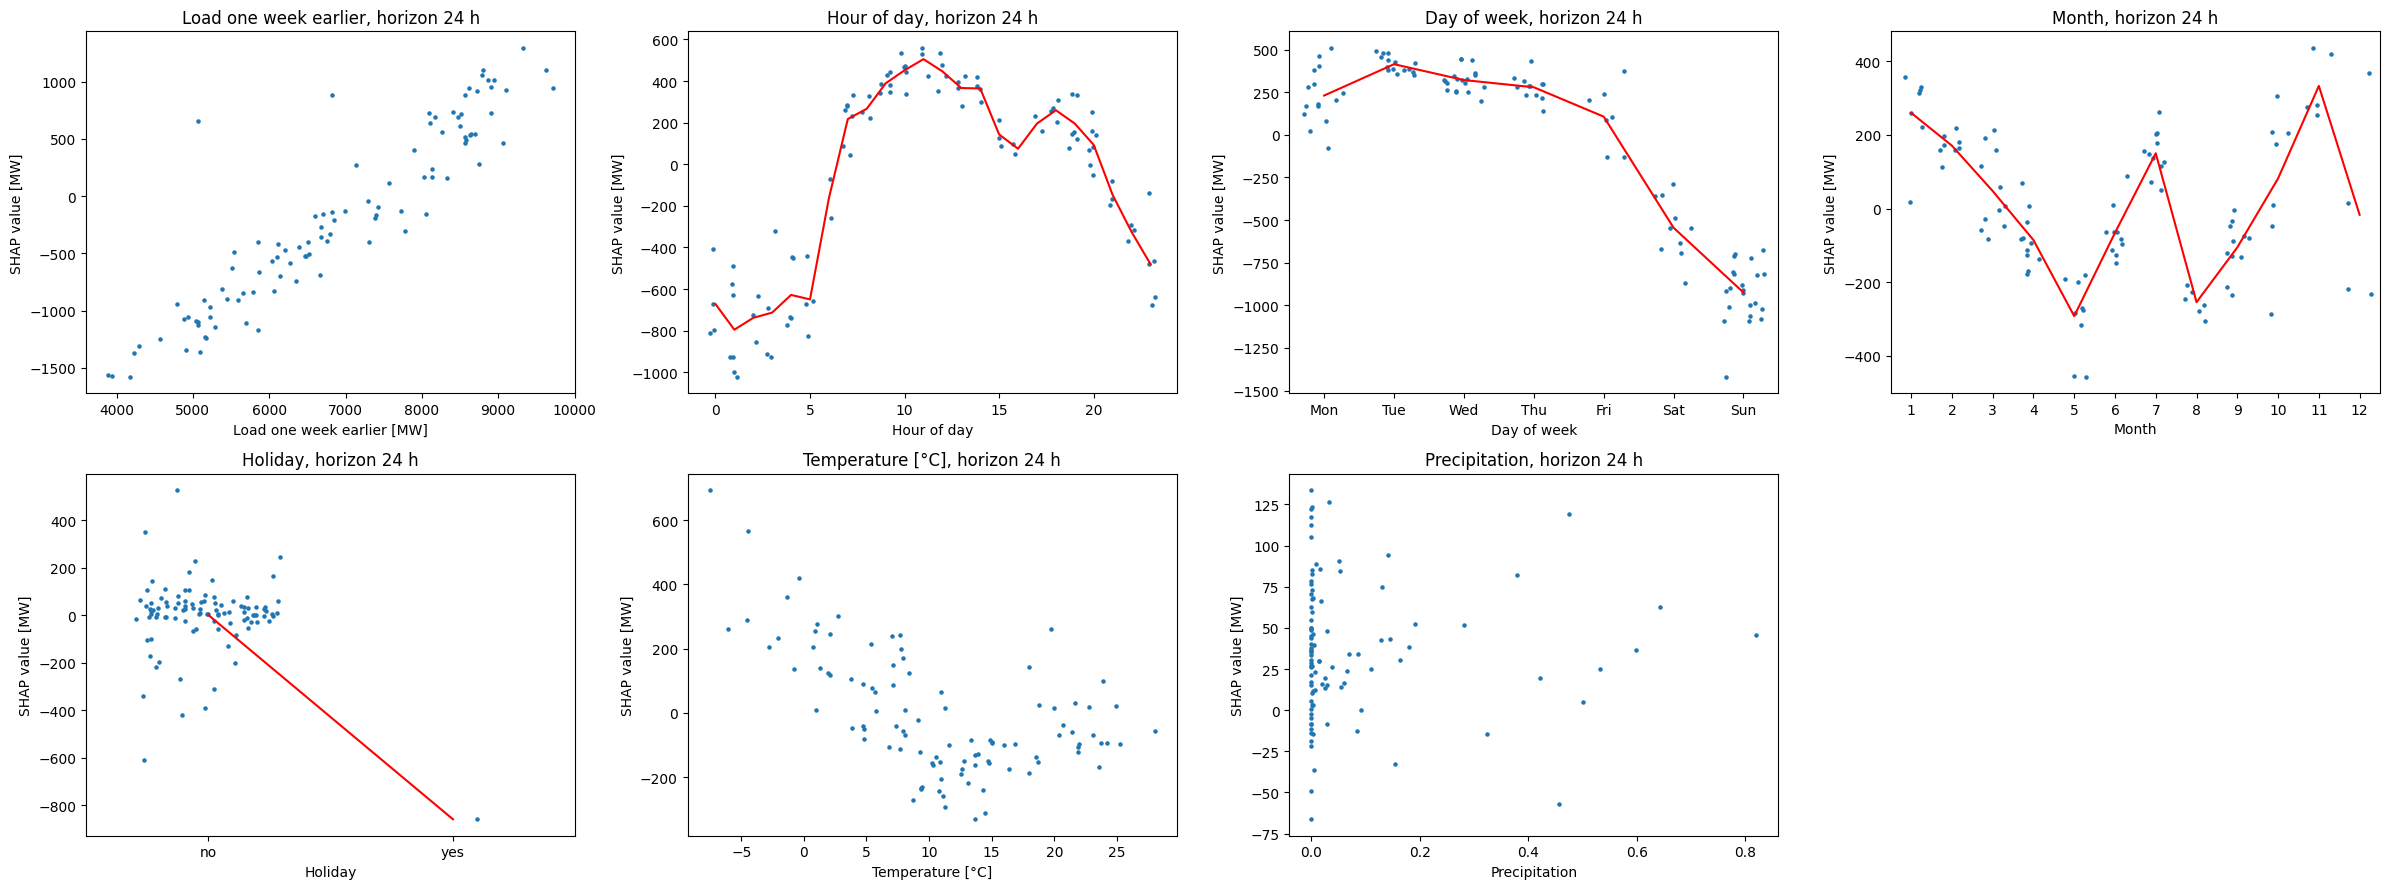

In [9]:
import math
from src.plot import plot_dependence

DEPENDENCE_HORIZON = 24  # plot the SHAP values of the 24th predicted hour; None plots all 168 hours

N_COLUMNS = 4
n_rows = math.ceil(len(model.feature_names) / N_COLUMNS)
fig, axs = plt.subplots(n_rows, N_COLUMNS, figsize=(6 * N_COLUMNS, 4.5 * n_rows))
for ax, feature in zip(axs.flat, model.feature_names):
    plot_dependence(explanations, feature, horizon=DEPENDENCE_HORIZON, ax=ax)
for ax in axs.flat[len(model.feature_names):]:
    ax.set_visible(False)
fig.tight_layout()
plt.show()